Last updated January 30, 2026

In [1]:
import os
import random

# plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype

# sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# scipy
from scipy.stats import entropy
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import cophenet
from fastcluster import linkage # faster version of linkage
from scipy.stats import ranksums
from statsmodels.stats.multitest import multipletests

# tensorly imports
import tensorly as tl
from tensorly.decomposition import non_negative_parafac, constrained_parafac
from tensorly.cp_tensor import cp_normalize

# pytorch imports
import torch
import torch.nn.functional as F

import sys
print(sys.version)

# settings
tl.set_backend('pytorch')

3.9.22 | packaged by conda-forge | (main, Apr 14 2025, 23:36:04) 
[Clang 18.1.8 ]


In [2]:
method_use = "non_negative_parafac"
root_dir = "/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem/"
input_dir = root_dir + "ProcessedData/" + "Sussman2024/" + "tensor_decomposition/" + "l1_top_10000_vf/" + "input_original/" 

In [3]:
min_rank = 1
max_rank = 10

# Create tensor object using Tensorly

In [4]:
sample_metadata_df = pd.read_csv(root_dir + "ExternalData/" + "Sussman_2024/" + "level3_sample_metadata.tsv", sep = "\t")
samples_use = sample_metadata_df["orig.ident"].tolist()

In [5]:
input_files = sorted(os.listdir(input_dir))
input_files = [i for i in input_files if i != ".DS_Store"]
data_list = []
all_samples = []
for filename in input_files:
    data = pd.read_csv(input_dir + filename, sep = "\t")
    data = np.log2(data + 1)
    all_genes = data.index.tolist()
    all_celltypes = data.columns.tolist()
    sample_id = filename.replace(".tsv", "")
    if sample_id in samples_use:
        data_list.append(data.values)
        all_samples.append(sample_id)

In [6]:
data_tensor = tl.tensor(torch.stack([torch.from_numpy(arr) for arr in data_list]))
print(data_tensor.shape) # samples x genes x cell type labels

torch.Size([63, 10000, 5])


In [7]:
data_tensor = data_tensor.permute(1, 0, 2)
print(data_tensor.shape) # genes x samples x cell type labels

torch.Size([10000, 63, 5])


# Run decomposition multiple iterations
I ran this three times with different seeds:  
non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777  
non_negative_parafac_5000_iter_tolerance_e_32_n=30_1_to_20_seed_123  
non_negative_parafac_5000_iter_tolerance_e_32_n=50_1_to_20_seed_42  

In [8]:
output_dir = root_dir + '/ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777/'
os.makedirs(output_dir, exist_ok=True)

In [9]:
def run_tensor_decomposition(tensor, rank, random_state, method_use, save_result=True):

    output_filename = 'tensor_rank_' + str(rank) + '_random_state=' + str(random_state) + '.pt'
    output_filepath = output_dir + "/" + output_filename
    print(output_filepath)
    
    if os.path.exists(output_filepath):
        print("file exists, reading in file")
        result = torch.load(output_filepath, weights_only=False)
        
    else:
        if method_use == "non_negative_parafac_l1_reg":
            result = non_negative_parafac_l1_reg(tensor, rank=rank, seed=random_state, l1_weight = 1e-5, lr = 1e-2)
        elif method_use == "non_negative_parafac":
            result = non_negative_parafac(tensor, init="random", rank=rank, n_iter_max=5000, tol=1e-32, random_state=random_state)
        else:
            raise Exception("Unknown method: " + method_use)
    
        if save_result:
            torch.save(result, output_filepath)
    
    return result


def run_decomposition_n_iters(tensor, rank, method_use, n_iters):
    fits = []
    random_states = []
    for i in range(n_iters):
        if (i + 1) % 1 == 0:
            print("iter " + str(i + 1))
        random_state = random.randint(0, 2**32 - 1)
        weights, factors = run_tensor_decomposition(tensor, rank, random_state, method_use)
        tensor_reconstructed = tl.cp_to_tensor((weights, factors))
        error = tl.norm(tensor - tensor_reconstructed) / tl.norm(tensor)
        fit = 1 - error.item()
        fits.append(fit)
        random_states.append(random_state)
    return fits, random_states


rank = 1
iter 1
/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem//ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777//tensor_rank_1_random_state=984982403.pt
file exists, reading in file
iter 2
/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem//ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777//tensor_rank_1_random_state=3231174163.pt
file exists, reading in file
iter 3
/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem//ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777//tensor_rank_1_random_state=3962945185.pt
file exists, reading in file
iter 4
/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/S

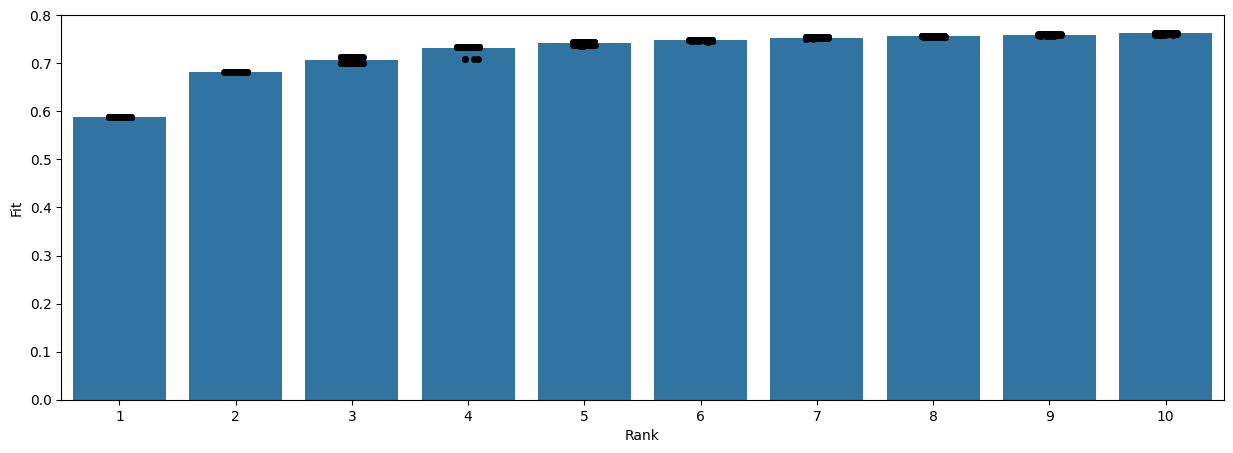

In [10]:
run_tensor_decomp = True

if run_tensor_decomp:

    random.seed(777)
    
    df = pd.DataFrame()
    
    for rank in range(min_rank, max_rank + 1):
        print("rank = " + str(rank))
        fits, random_states = run_decomposition_n_iters(data_tensor, rank, method_use, n_iters=100)
        rank_df = pd.DataFrame({'random_state': random_states, 'fit': fits})
        rank_df[["rank"]] = rank
        df = pd.concat([df, rank_df], axis=0, ignore_index=True)
        print(rank_df)
    
    df.to_csv(output_dir + 'rank_vs_fit_' + str(min_rank) + '_to_' + str(max_rank) + '.tsv', sep='\t', index=False)


    # plot figure rank vs fit
    plt.figure(figsize=(15, 5))
    ax = sns.barplot(x='rank', y='fit', data=df, errorbar='se')
    sns.stripplot(x='rank', y='fit', data=df, color='black', ax=ax, jitter=True)
    plt.xlabel('Rank')
    plt.ylabel('Fit')
    plt.savefig(output_dir + "rank_vs_fit.pdf") 
    plt.show()